# Семь торговых систем: суть и сделки

Это продолжение прогона из [`docs/RESULTS_SEVEN_FAMILIES.md`](../docs/RESULTS_SEVEN_FAMILIES.md).
Там таблицы и вероятности; здесь — что каждая система **делает** и как выглядят её сделки.

Все графики строятся не по пересказу, а по тем же скриптам
(`research/seven_families/`), что дали отчёт: сигнал → целевая позиция → движок →
журнал сделок. Исполнение в движке — next-open по построению, поэтому маркер входа
стоит на том баре и по той цене, которые были доступны в момент решения.

### Как читать графики

| Элемент | Значение |
|---|---|
| Чёрная линия | цена сигнального ряда (ratio-adjusted непрерывный) |
| Цветные линии | механизм системы: средние, канал, ориентир в прошлом |
| ▲ синий / ▼ красный | открытие записи о сделке, в длинную / короткую сторону |
| ○ | закрытие записи — полное или частичное |
| Синий фон / красный фон | система в длинной / короткой позиции |
| Фон без заливки | вне рынка (умеют только семейства 3 и 7) |

Цены на панелях сделок — **ratio-adjusted** непрерывный ряд, а не котировки: маркеры
должны стоять на том ряду, по которому исполнялись сделки. Уровни этого ряда совпадают
с котировками в конце истории и расходятся с ними тем сильнее, чем дальше в прошлое.

### Запись о сделке — не то же, что разворот позиции

Движок закрывает запись всякий раз, когда закрывается **какое-то количество**, а
волатильностный сайзинг с полосой 20% регулярно сокращает позицию, не переворачивая её.
Поэтому записей о сделках больше, чем разворотов: у TSMOM на Brent 348 записей против
230 смен направления. В таблице ниже приведены обе величины, а маркер входа стоит на
**средней цене входа** записи — она может отличаться от цены бара, если позицию набирали
частями. Обиходное «сколько сделок» — это столбец «разворотов позиции»; число в отчёте
(135 для этой ячейки) — записи вне выборки.

### Почему синий и красный, а не зелёный и красный

Зелёный против красного — отраслевой стандарт и худшая возможная пара: именно её не
различают при дейтеранопии, то есть примерно 8% мужчин. Синий против красного несёт ту
же полярность (холодный против тёплого) и остаётся различимым. Направление сделки
дополнительно закодировано формой маркера, поэтому график читается и в чёрно-белой печати.


## Суть семи систем на одной странице

Шесть из семи систем — это один и тот же тезис, записанный по-разному: **цена
продолжает движение**. Различаются только способ измерить движение и способ выйти.

| № | Система | Чем измеряется сигнал | Выход в нуль | Что должно быть верно, чтобы она работала |
|---|---|---|---|---|
| 1 | Time-Series Momentum | знак доходности за N дней | нет | тренды длиннее N дней встречаются чаще, чем ложные пересечения |
| 2 | Dual Moving Average | знак разности двух средних | нет | сглаживание отсекает шум дешевле, чем стоит его задержка |
| 3 | Channel Breakout | пробой N-дневного экстремума | **да** | новый экстремум меняет поведение участников, а не просто случается |
| 4 | Cross-sectional momentum | относительная сила рынков | нет | порядок рынков устойчивее, чем их общее направление |
| 5 | Carry / term structure | наклон срочной кривой | **да** (внутри порога) | премия за дефицит реальна и больше издержек ролла |
| 6 | MA + portfolio | то же, что 2, но на портфеле | нет | тренды на рынках не синхронны, и просадки не складываются |
| 7 | Momentum + reversal | моментум минус долгосрочная реверсия | **да** (при расхождении) | два горизонта описывают два разных процесса |

Седьмая и пятая — единственные, у которых тезис **не** про продолжение движения:
carry зарабатывает на форме кривой даже при неподвижной цене, а reversal утверждает
прямо противоположное моментуму на другом горизонте.

Всё остальное у семи систем общее и задано стендом, а не семейством:

* **Размер позиции** — под целевую волатильность 15% годовых, окно 20 дней,
  плечо не выше 3. Поэтому все кривые капитала сопоставимы: у них одинаковый риск
  по построению, а не одинаковый номинал.
* **Полоса ребалансировки 20%** — позиция не трогается, пока не отошла от цели
  больше чем на пятую часть. Без неё волатильностный сайзинг торгует каждый день:
  на 3 828 барах это 1 796 сделок и 16% капитала в издержках.
* **Издержки** — 7 б.п. за полный оборот в базовом сценарии (полуспред 2, слиппедж
  1 плюс 5% волатильности бара, комиссия 0.5), в базисных пунктах от ноционала.


In [1]:
import os
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Исследовательские скрипты — источник истины: графики показывают ровно те
# сделки, которые попали в отчёт, а не их пересказ.
ROOT = next(p for p in Path.cwd().parents if (p / "research" / "seven_families").is_dir())
sys.path.insert(0, str(ROOT / "research" / "seven_families"))

CANDIDATES = [ROOT / "data" / "raw" / "moex_algopack", Path("/home/user/moex")]
DATA = next((p for p in CANDIDATES if p.is_dir()), None)
if DATA is None:
    raise FileNotFoundError(f"не найден каталог AlgoPack; искал: {[str(p) for p in CANDIDATES]}")
os.environ["EXCHANGE_MOEX_DATA"] = str(DATA)

import families as F          # noqa: E402
import harness as H           # noqa: E402
import run_all as RA          # noqa: E402

print("данные:", DATA)
print("капитал", f"{H.CAPITAL:,.0f}", "| целевая волатильность", H.TARGET_VOL,
      "| полоса ребалансировки", H.REBALANCE_BAND)


данные: /home/user/moex
капитал 1,000,000 | целевая волатильность 0.15 | полоса ребалансировки 0.2


In [2]:
# --- Палитра --------------------------------------------------------------
# Дивергентная пара синий<->красный несёт полярность: long против short,
# прибыльная сделка против убыточной. Нейтральный серый — середина (вне рынка).
# Зелёный/красный — отраслевой стандарт и худший выбор: это ровно та пара,
# которую не различает 8% мужчин. Форма маркера (треугольник вверх/вниз)
# дублирует цвет, поэтому направление сделки читается и без цвета.
LONG, SHORT = "#2a78d6", "#e34948"
SERIES_1, SERIES_2 = "#2a78d6", "#eb6834"
NEUTRAL = "#f0efec"
SURFACE, INK, INK_2 = "#fcfcfb", "#0b0b0b", "#52514e"
MUTED, GRID, AXIS = "#898781", "#e1e0d9", "#c3c2b7"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.linewidth": 0.8, "axes.edgecolor": AXIS,
    "lines.linewidth": 2.0, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 130,
})


def frame(ax, title="", subtitle="", ylabel="", grid_axis="y"):
    ax.grid(True, axis=grid_axis, color=GRID, linewidth=0.8, linestyle="-", zorder=0)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    if title:
        ax.set_title(title, color=INK, fontsize=12.5, fontweight="semibold", loc="left", pad=16)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=INK_2, fontsize=9.5, va="bottom")
    if ylabel:
        ax.set_ylabel(ylabel, color=INK_2, fontsize=9.5)
    ax.tick_params(length=3, color=AXIS)


def date_ticks(ax, index, n=7, x0=0):
    """Даты на порядковой оси: бары равной ширины, без дыр на выходных.

    x0 — смещение окна: данные нарисованы в координатах исходного ряда,
    поэтому и подписи должны стоять там же, иначе они уезжают за пределы оси.
    """
    pos = np.linspace(0, len(index) - 1, n).round().astype(int)
    ax.set_xticks(pos + x0)
    ax.set_xticklabels([index[p].strftime("%m.%y") for p in pos])


def below_legend(ax, ncol=4):
    """Легенда под осью: над данными она закрывает именно то, что показывает."""
    ax.legend(loc="upper left", bbox_to_anchor=(0, -0.13), ncol=ncol,
              handletextpad=0.5, columnspacing=1.6, borderaxespad=0)


## Стенд: данные, конфигурации, журнал сделок

Ниже загружаются оба инструмента и прогоняются двенадцать ячеек «семейство × рынок»
с теми параметрами, которые были отобраны на in-sample. Таблица — это уже сами сделки:
сколько их, сколько длинных, сколько прибыльных и как долго система держала позицию.

In [3]:
UNIVERSE = H.load_universe()
PANEL_ALL = {r: p["bars"] for r, p in UNIVERSE.items()}
COMMON = PANEL_ALL["NG"].index.intersection(PANEL_ALL["BR"].index)

# Конфигурации, отобранные на in-sample в прогоне 2026-10-07
# (docs/RESULTS_SEVEN_FAMILIES.md, раздел 1). Здесь они заданы явно: ноутбук
# показывает сделки уже выбранной системы, а не повторяет отбор.
WINNERS = {
    ("1_tsmom", "BR"): {"lookback": 40},
    ("1_tsmom", "NG"): {"lookback": 90},
    ("2_dual_ma", "BR"): {"fast": 20, "slow": 60},
    ("2_dual_ma", "NG"): {"fast": 20, "slow": 150},
    ("3_breakout", "BR"): {"entry": 40, "exit_": 20},
    ("3_breakout", "NG"): {"entry": 20, "exit_": 10},
    ("4_cross_sectional", "NG+BR"): {"lookback": 120},
    ("5_carry", "BR"): {"smooth": 1, "threshold": 0.15},
    ("5_carry", "NG"): {"smooth": 1, "threshold": 0.15},
    ("6_portfolio_ma", "NG+BR"): {"fast": 20, "slow": 100},
    ("7_mom_reversal", "BR"): {"momentum": 60, "reversal": 750},
    ("7_mom_reversal", "NG"): {"momentum": 60, "reversal": 500},
}


def run_leg(family, market, params):
    """Одна нога системы: сигнал -> целевая позиция -> движок -> сделки.

    Возвращает то, что видел бэктест: бары, по которым считался сигнал,
    сам сигнал, удерживаемую позицию после полосы ребалансировки, журнал
    сделок и кривую капитала. Исполнение — next-open, по построению движка.
    """
    if family in F.PANEL:
        panel = {r: b.loc[COMMON] for r, b in PANEL_ALL.items()}
        signal = F.PANEL[family](panel, **params)[market]
        bars, ppy = panel[market], UNIVERSE[market]["ppy"]
        target = RA.positions(bars, ppy, signal, legs=len(panel))
    else:
        bars = PANEL_ALL[market]
        ppy = UNIVERSE[market]["ppy"]
        signal = F.SINGLE[family](bars, **params)
        target = RA.positions(bars, ppy, signal)
    result, metrics = H.backtest(bars, target, symbol=market, ppy=ppy)
    return {
        "bars": bars, "signal": signal, "target": target, "ppy": ppy,
        "trades": result.trades, "equity": result.equity, "position": result.position,
        "metrics": metrics, "is_end": RA.split(bars.index)[0][-1],
    }


LEGS = {}
for (family, market), params in WINNERS.items():
    for leg in (("NG", "BR") if market == "NG+BR" else (market,)):
        LEGS[(family, market, leg)] = run_leg(family, leg, params)

def direction_changes(position):
    """Сколько раз позиция меняла знак — это и есть «сделки» в обиходном смысле."""
    sign = np.sign(position.to_numpy(float))
    sign = sign[sign != 0]
    return int((np.diff(sign) != 0).sum())


summary = pd.DataFrame([
    {"семейство": f, "рынок": m, "нога": leg,
     "разворотов позиции": direction_changes(v["position"]),
     "записей о сделках": len(v["trades"]),
     "из них long": int((v["trades"]["direction"] > 0).sum()) if len(v["trades"]) else 0,
     "прибыльных": int((v["trades"]["net_pnl"] > 0).sum()) if len(v["trades"]) else 0,
     "медиана, баров": float(v["trades"]["bars_held"].median()) if len(v["trades"]) else np.nan,
     "в рынке, % времени": float((v["position"] != 0).mean() * 100)}
    for (f, m, leg), v in LEGS.items()
])
summary.round(1)


,семейство,рынок,нога,разворотов позиции,записей о сделках,из них long,прибыльных,"медиана, баров","в рынке, % времени"
0,1_tsmom,BR,BR,230,348,182,170,5.0,98.9
1,1_tsmom,NG,NG,78,131,65,61,5.0,94.9
2,2_dual_ma,BR,BR,58,175,91,111,16.0,98.4
3,2_dual_ma,NG,NG,15,66,32,40,15.5,91.6
4,3_breakout,BR,BR,36,130,72,92,17.0,78.1
5,3_breakout,NG,NG,40,79,45,51,10.0,73.3
6,4_cross_sectional,NG+BR,NG,73,130,60,66,5.0,93.2
7,4_cross_sectional,NG+BR,BR,73,119,63,48,6.0,93.2
8,5_carry,BR,BR,36,135,77,77,15.0,61.3
9,5_carry,NG,NG,22,78,29,43,15.0,89.0


In [4]:
def shade_position(ax, pos, x0):
    """Фон: синий — в длинной позиции, красный — в короткой, пусто — вне рынка."""
    sign = np.sign(pos.to_numpy(float))
    x = np.arange(len(sign)) + x0
    lo, hi = ax.get_ylim()
    for value, colour in ((1.0, LONG), (-1.0, SHORT)):
        ax.fill_between(x, lo, hi, where=(sign == value), color=colour, alpha=0.07,
                        linewidth=0, zorder=0)
    ax.set_ylim(lo, hi)


def mark_trades(ax, trades, index, x0, size=9):
    """Входы — треугольник по направлению, выходы — кольцо.

    Форма маркера дублирует цвет: направление сделки читается и в ч/б.
    """
    loc = {t: i for i, t in enumerate(index)}
    shown = {"long": False, "short": False, "exit": False}
    for _, t in trades.iterrows():
        i, j = loc.get(t["entry_time"]), loc.get(t["exit_time"])
        if i is None:
            continue
        long_ = t["direction"] > 0
        ax.plot([i + x0], [t["entry_price"]], marker="^" if long_ else "v",
                markersize=size, color=LONG if long_ else SHORT, zorder=5,
                markeredgecolor=SURFACE, markeredgewidth=1.5,
                label=("вход long" if long_ else "вход short")
                if not shown["long" if long_ else "short"] else None)
        shown["long" if long_ else "short"] = True
        if j is not None:
            ax.plot([j + x0], [t["exit_price"]], marker="o", markersize=size - 3,
                    markerfacecolor=SURFACE, markeredgecolor=MUTED, markeredgewidth=1.6,
                    zorder=5, label="выход" if not shown["exit"] else None)
            shown["exit"] = True


def trade_pnl(ax, trades, ppy_label=""):
    """Результат каждой сделки: стебель от нуля, цвет и знак совпадают."""
    if not len(trades):
        ax.text(0.5, 0.5, "сделок нет", transform=ax.transAxes, ha="center", color=MUTED)
        return
    pnl = trades["net_pnl"].to_numpy(float) / H.CAPITAL * 100.0
    x = np.arange(len(pnl))
    for mask, colour in ((pnl >= 0, LONG), (pnl < 0, SHORT)):
        if mask.any():
            ax.vlines(x[mask], 0, pnl[mask], color=colour, linewidth=2.0)
            ax.plot(x[mask], pnl[mask], marker="o", markersize=4, linestyle="none",
                    color=colour, markeredgecolor=SURFACE, markeredgewidth=1.0)
    ax.axhline(0, color=AXIS, linewidth=0.8)
    best, worst = int(np.argmax(pnl)), int(np.argmin(pnl))
    for i in (best, worst):
        ax.annotate(f"{pnl[i]:+.1f}%", xy=(i, pnl[i]), xytext=(0, 6 if pnl[i] > 0 else -14),
                    textcoords="offset points", ha="center", color=INK_2, fontsize=9)
    ax.set_xlim(-1, len(pnl))
    span = float(np.nanmax(pnl) - np.nanmin(pnl)) or 1.0
    ax.set_ylim(float(np.nanmin(pnl)) - 0.18 * span, float(np.nanmax(pnl)) + 0.18 * span)
    ax.set_xlabel("сделки в порядке закрытия", color=MUTED, fontsize=9)


def equity_panel(ax, leg, title, subtitle):
    eq = leg["equity"] / H.CAPITAL * 100.0 - 100.0
    x = np.arange(len(eq))
    frame(ax, title, subtitle, ylabel="доходность, %")
    ax.plot(x, eq.to_numpy(float), color=SERIES_1, linewidth=2.0)
    ax.axhline(0, color=AXIS, linewidth=0.8)
    cut = eq.index.get_indexer([leg["is_end"]], method="nearest")[0]
    ax.axvline(cut, color=MUTED, linewidth=1.0, linestyle="-")
    ax.annotate("конец in-sample", xy=(cut, ax.get_ylim()[0]), xytext=(6, 8),
                textcoords="offset points", color=MUTED, fontsize=9, va="bottom",
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
    ax.annotate(f"{eq.iloc[-1]:+.1f}%", xy=(len(eq) - 1, eq.iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=INK_2,
                fontsize=9.5, fontweight="semibold")
    date_ticks(ax, eq.index)   # одна серия — легенда не нужна, её называет заголовок


def trades_figure(family, market, leg_name, window=320, overlay=None,
                  title="", mechanism="", extra=None, ylabel="непрерывный ряд (ratio), USD"):
    """Панели: механизм и сделки в окне, (опционально сигнал), капитал, сделки."""
    leg = LEGS[(family, market, leg_name)]
    bars, trades = leg["bars"], leg["trades"]
    x0 = max(len(bars) - window, 0)
    view = bars.iloc[x0:]
    px = view["close"]
    xs = np.arange(len(view)) + x0

    rows = [1.35] + ([0.55] if extra else []) + [1.0, 0.75]
    fig = plt.figure(figsize=(11.5, 3.1 * len(rows) + 1.4))
    gs = fig.add_gridspec(len(rows), 1, height_ratios=rows, hspace=0.75)

    ax = fig.add_subplot(gs[0])
    frame(ax, title or f"{family} · {leg_name}",
          mechanism, ylabel="непрерывный ряд (ratio), USD")
    ax.plot(xs, px.to_numpy(float), color=INK, linewidth=1.4, label="цена (сигнальный ряд)")
    if overlay is not None:
        overlay(ax, leg, x0, view)
    in_view = trades[(trades["entry_time"] >= view.index[0])]
    mark_trades(ax, in_view, bars.index, 0)
    shade_position(ax, leg["position"].iloc[x0:], x0)
    date_ticks(ax, view.index, x0=x0)
    ax.set_xlim(x0 - 2, x0 + len(view) + 1)
    below_legend(ax, ncol=5)

    if extra:
        axe = fig.add_subplot(gs[1])
        extra(axe, leg, x0, view)
        date_ticks(axe, view.index, x0=x0)
        axe.set_xlim(x0 - 2, x0 + len(view) + 1)

    equity_panel(fig.add_subplot(gs[1 + bool(extra)]), leg,
                 "Кривая капитала за весь период",
                 f"издержки базового сценария; отбор параметров закончился "
                 f"{leg['is_end'].date()}")

    ax3 = fig.add_subplot(gs[2 + bool(extra)])
    frame(ax3, "Результат каждой сделки",
          (f"за весь период: {len(trades)} сделок, прибыльных "
           f"{(trades['net_pnl'] > 0).mean():.0%}; в отчёте по этой ячейке "
           f"приведены только сделки вне выборки") if len(trades) else "",
          ylabel="% капитала")
    trade_pnl(ax3, trades)
    plt.show()


In [5]:
def ref_price(label, lag, colour):
    """Цена lag баров назад: сигнал — знак разницы с текущей ценой."""
    def draw(ax, leg, x0, view):
        ref = leg["bars"]["close"].shift(lag).iloc[x0:]
        ax.plot(np.arange(len(view)) + x0, ref.to_numpy(float), color=colour,
                linewidth=1.6, label=label)
    return draw


def ma_overlay(fast, slow):
    def draw(ax, leg, x0, view):
        from exchange.strategies.base import sma
        close = leg["bars"]["close"]
        x = np.arange(len(view)) + x0
        ax.plot(x, sma(close, fast).iloc[x0:].to_numpy(float), color=SERIES_1,
                linewidth=1.8, label=f"SMA {fast}")
        ax.plot(x, sma(close, slow).iloc[x0:].to_numpy(float), color=SERIES_2,
                linewidth=1.8, label=f"SMA {slow}")
    return draw


def channel_overlay(entry, exit_):
    def draw(ax, leg, x0, view):
        bars = leg["bars"]
        x = np.arange(len(view)) + x0
        up = bars["high"].rolling(entry).max().shift(1).iloc[x0:]
        dn = bars["low"].rolling(entry).min().shift(1).iloc[x0:]
        xu = bars["high"].rolling(exit_).max().shift(1).iloc[x0:]
        xd = bars["low"].rolling(exit_).min().shift(1).iloc[x0:]
        ax.plot(x, up.to_numpy(float), color=SERIES_1, linewidth=1.6,
                label=f"канал входа {entry} дн.")
        ax.plot(x, dn.to_numpy(float), color=SERIES_1, linewidth=1.6)
        ax.plot(x, xu.to_numpy(float), color=SERIES_2, linewidth=1.1,
                label=f"канал выхода {exit_} дн.")
        ax.plot(x, xd.to_numpy(float), color=SERIES_2, linewidth=1.1)
    return draw


def rival_overlay(other, lookback):
    """Второй рынок, приведённый к началу окна: сравниваются относительные силы."""
    def draw(ax, leg, x0, view):
        rival = PANEL_ALL[other]["close"].reindex(leg["bars"].index).ffill()
        scaled = rival / float(rival.iloc[x0]) * float(view["close"].iloc[0])
        ax.plot(np.arange(len(view)) + x0, scaled.iloc[x0:].to_numpy(float),
                color=SERIES_2, linewidth=1.6,
                label=f"{other}, приведён к началу окна")
    return draw


def carry_panel(threshold):
    def draw(ax, leg, x0, view):
        carry = leg["bars"]["carry"].iloc[x0:]
        x = np.arange(len(view)) + x0
        frame(ax, "", f"прокси carry по коэффициентам ролла; порог ±{threshold}",
              ylabel="годовой carry")
        ax.plot(x, carry.to_numpy(float), color=INK, linewidth=1.6, label="carry")
        ax.axhline(0, color=AXIS, linewidth=0.8)
        for sign, colour, lab in ((1, LONG, "порог long"), (-1, SHORT, "порог short")):
            ax.axhline(sign * threshold, color=colour, linewidth=1.2,
                       label=lab)
        ax.fill_between(x, threshold, carry.to_numpy(float),
                        where=carry.to_numpy(float) > threshold, color=LONG, alpha=0.12,
                        linewidth=0)
        ax.fill_between(x, -threshold, carry.to_numpy(float),
                        where=carry.to_numpy(float) < -threshold, color=SHORT, alpha=0.12,
                        linewidth=0)
        below_legend(ax, ncol=4)
    return draw


def ref_pair(lag_a, label_a, lag_b, label_b):
    """Два ориентира сразу: горизонт моментума и горизонт реверсии."""
    def draw(ax, leg, x0, view):
        close = leg["bars"]["close"]
        x = np.arange(len(view)) + x0
        for lag, lab, colour in ((lag_a, label_a, SERIES_1), (lag_b, label_b, SERIES_2)):
            ax.plot(x, close.shift(lag).iloc[x0:].to_numpy(float), color=colour,
                    linewidth=1.6, label=lab)
    return draw


## 1. Time-Series Momentum

**Утверждение.** Если инструмент за последние `lookback` дней вырос — он продолжит расти;
если упал — продолжит падать. Позиция всегда есть: long или short, нуля не бывает.

**Механизм.** Информация в сырьевые цены приходит медленно: запасы, погода, решения ОПЕК
отыгрываются неделями, а не в один день. Плюс поведенческий канал — хеджеры и фонды
подстраивают позиции постепенно. Оба канала превращают новость в тренд.

**Что видно на графике.** Чёрная линия — цена, синяя — цена `lookback` дней назад.
Сигнал — знак разницы между ними: цена выше ориентира → long, ниже → short. Переворот
происходит в точке их пересечения, и именно там стоят маркеры сделок.

**Чем система ломается.** На боковом рынке цена пересекает свой лаг многократно, система
переворачивается на каждом касании и платит издержки за каждый переворот.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


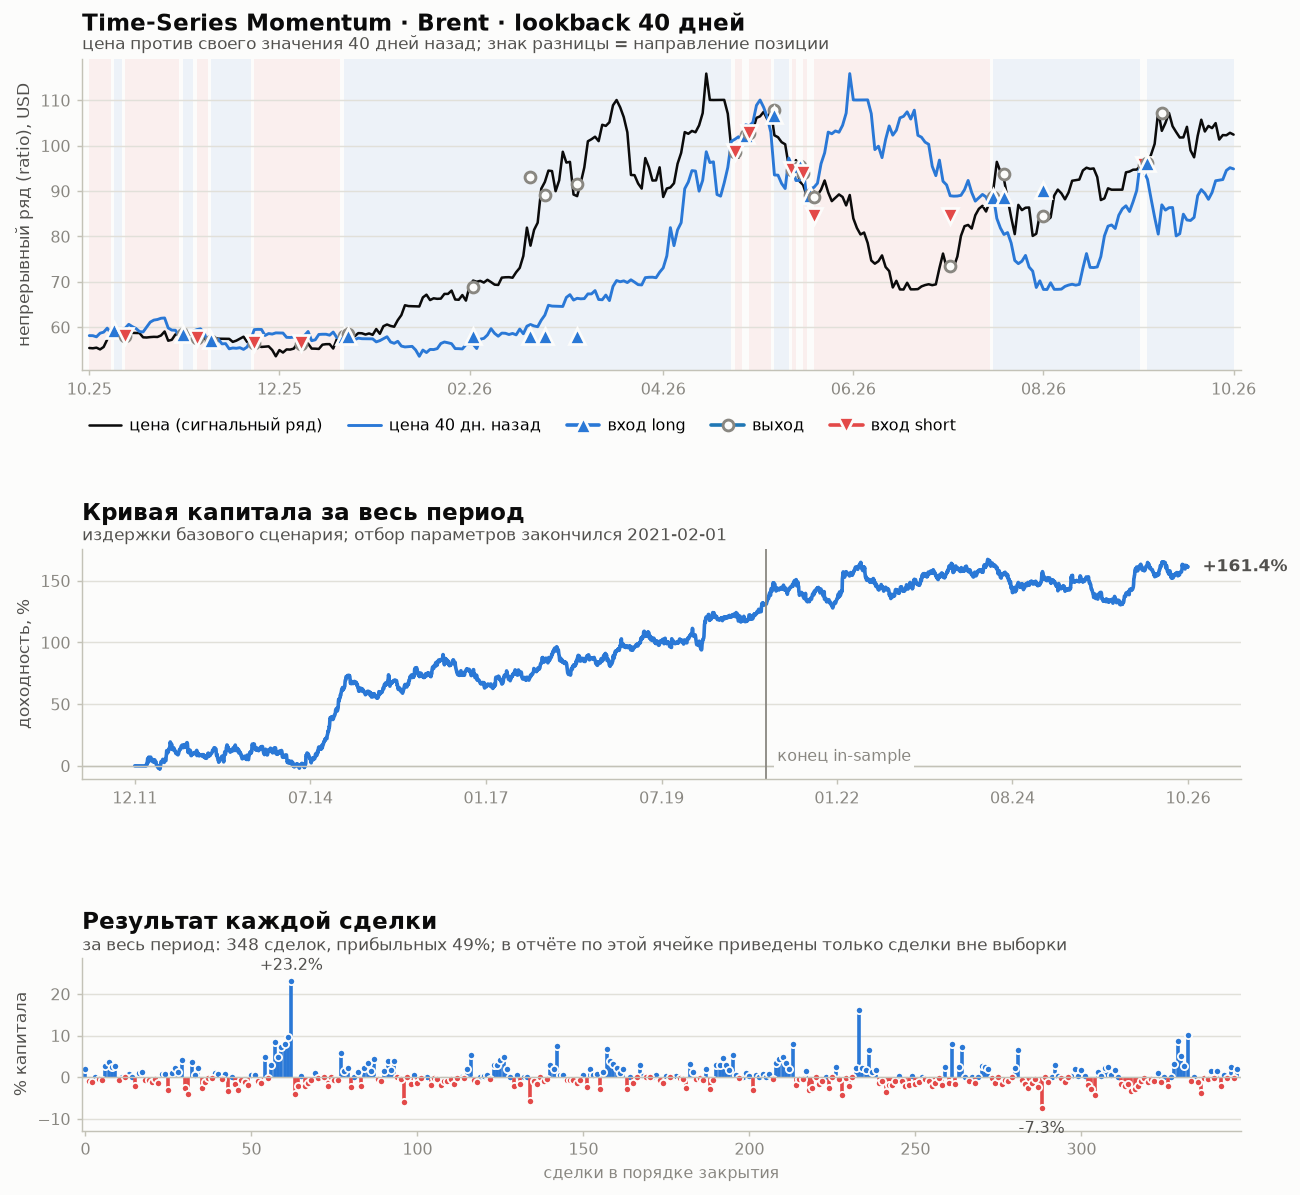

In [6]:
trades_figure(
    "1_tsmom", "BR", "BR", window=320, overlay=ref_price("цена 40 дн. назад", 40, SERIES_1),
    title="Time-Series Momentum · Brent · lookback 40 дней",
    mechanism="цена против своего значения 40 дней назад; знак разницы = направление позиции",
)


### То же семейство на газе

Правило не изменилось, изменился рынок. На NG отобранный lookback вдвое длиннее (90 дней),
а вне выборки Шарп отрицательный: −0.38. Сравнение двух графиков — это и есть содержание
результата из отчёта.

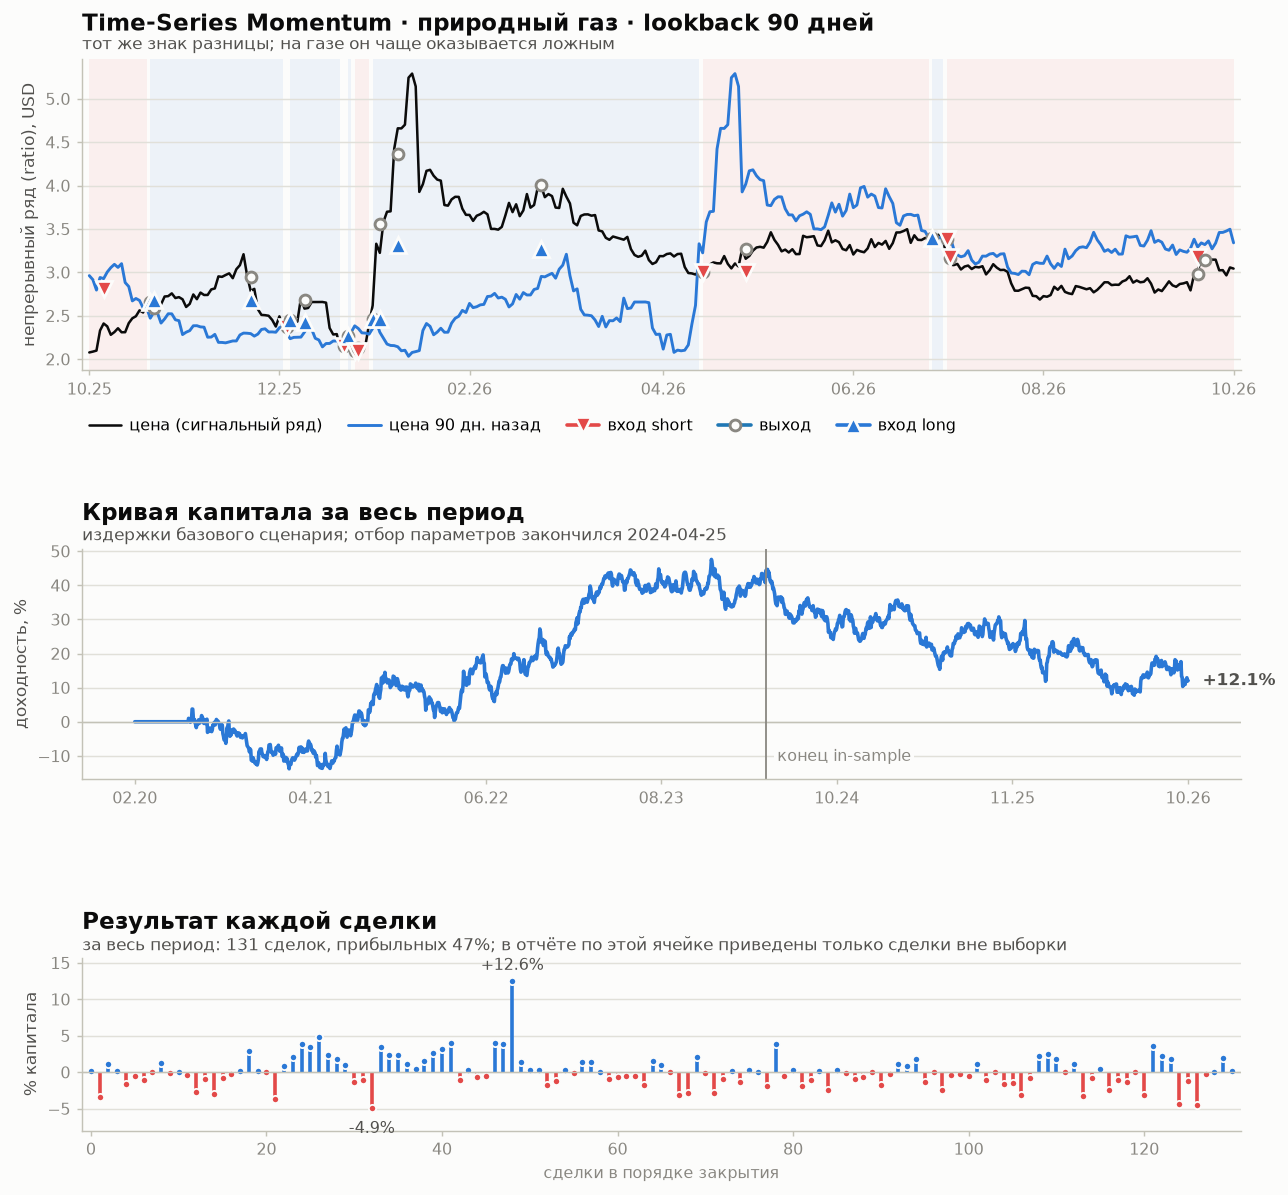

In [7]:
trades_figure(
    "1_tsmom", "NG", "NG", window=320, overlay=ref_price("цена 90 дн. назад", 90, SERIES_1),
    title="Time-Series Momentum · природный газ · lookback 90 дней",
    mechanism="тот же знак разницы; на газе он чаще оказывается ложным",
)


## 2. Dual Moving Average

**Утверждение.** Быстрая средняя выше медленной → тренд вверх → long; ниже → short.

**Механизм.** Тот же, что у TSMOM, но тренд измеряется не одной точкой в прошлом, а двумя
сглаженными уровнями. Это снижает чувствительность к единичному выбросу: один аномальный
день сдвигает быструю среднюю на 1/`fast` своей величины, а не переворачивает сигнал.

**Что видно на графике.** Две средние; каждое их пересечение — переворот позиции.
Сделок заметно меньше, чем у TSMOM на том же рынке (69 против 135), и именно поэтому
издержки здесь 5% капитала против 14%.

**Чем система ломается.** Сглаживание — это задержка. Разворот тренда система признаёт
позже, чем он случился, и отдаёт часть движения назад.

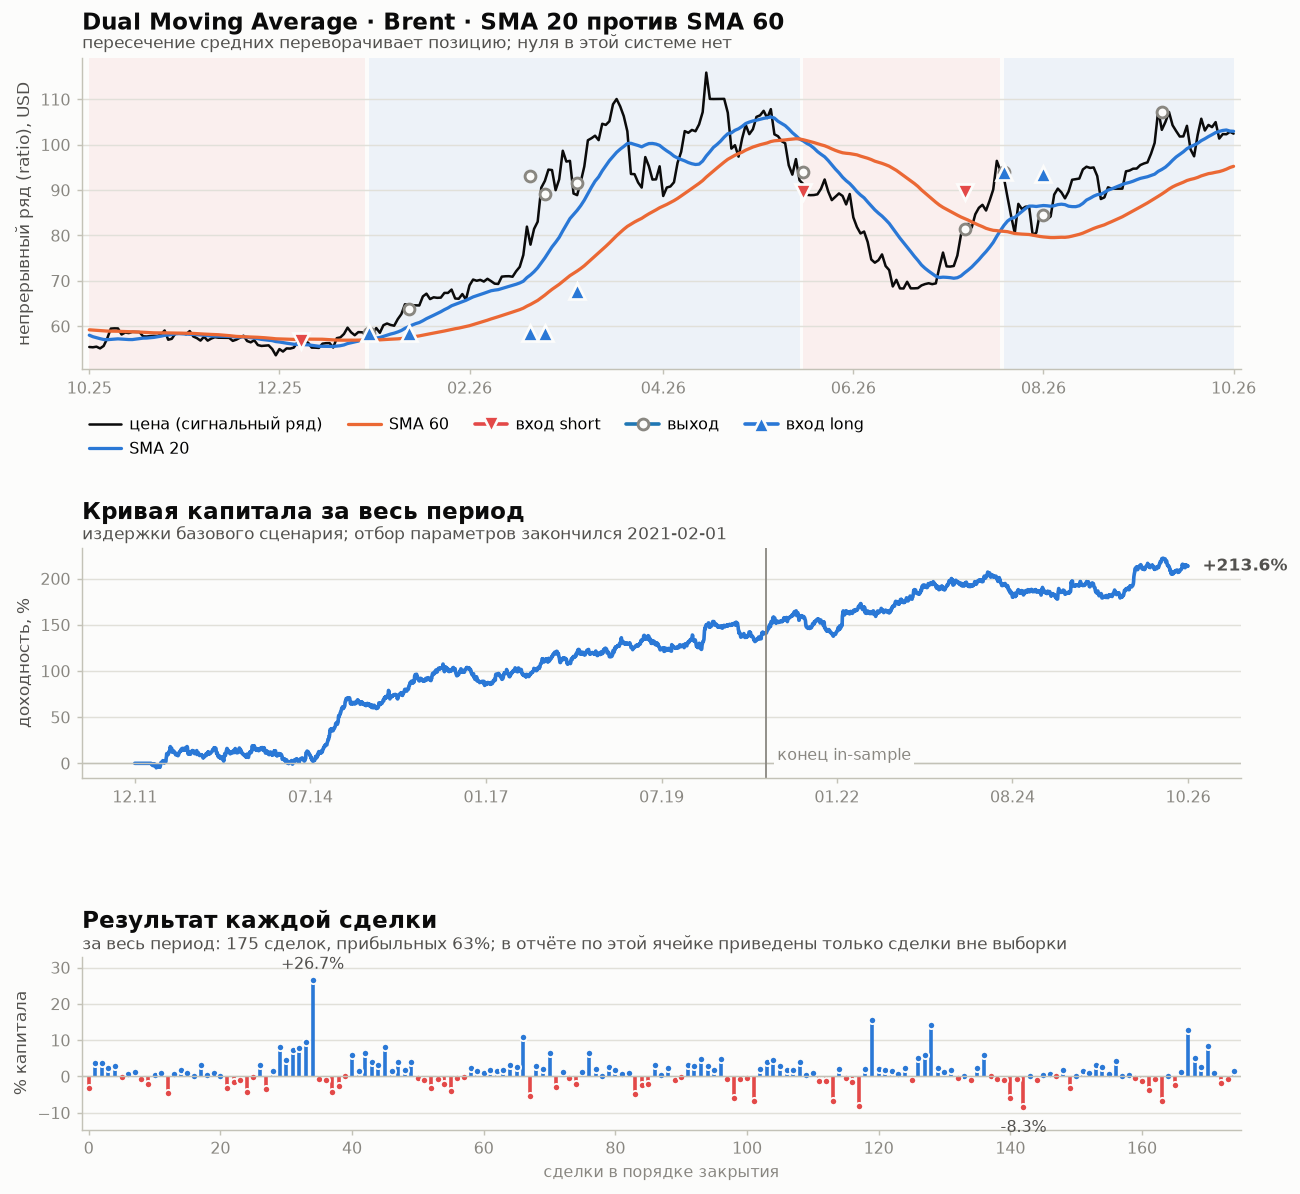

In [8]:
trades_figure(
    "2_dual_ma", "BR", "BR", window=320, overlay=ma_overlay(20, 60),
    title="Dual Moving Average · Brent · SMA 20 против SMA 60",
    mechanism="пересечение средних переворачивает позицию; нуля в этой системе нет",
)


## 3. Channel Breakout

**Утверждение.** Пробой максимума за `entry` дней — сигнал в long; пробой минимума —
в short. Выход — по обратному пробою более короткого канала (`exit_`), и это единственная
из семи систем, которая умеет выходить **в нуль**, а не переворачиваться.

**Механизм.** Новый экстремум означает, что цену приняли на уровне, где её раньше
отвергали: прежние продавцы исчерпаны, стоп-заявки сняты. Это классический тестируемый
смысл пробоя.

**Что видно на графике.** Синие линии — канал входа (40 дней), оранжевые — канал выхода
(20 дней). Каналы построены по барам **строго до текущего**: иначе касание уровня было бы
ретроспективным наблюдением, а не торгуемым событием. Фон без заливки — периоды вне рынка.

**Чем система ломается.** Ложный пробой: цена выходит за канал на один день и возвращается.
Система платит вход и выход, не получив движения.

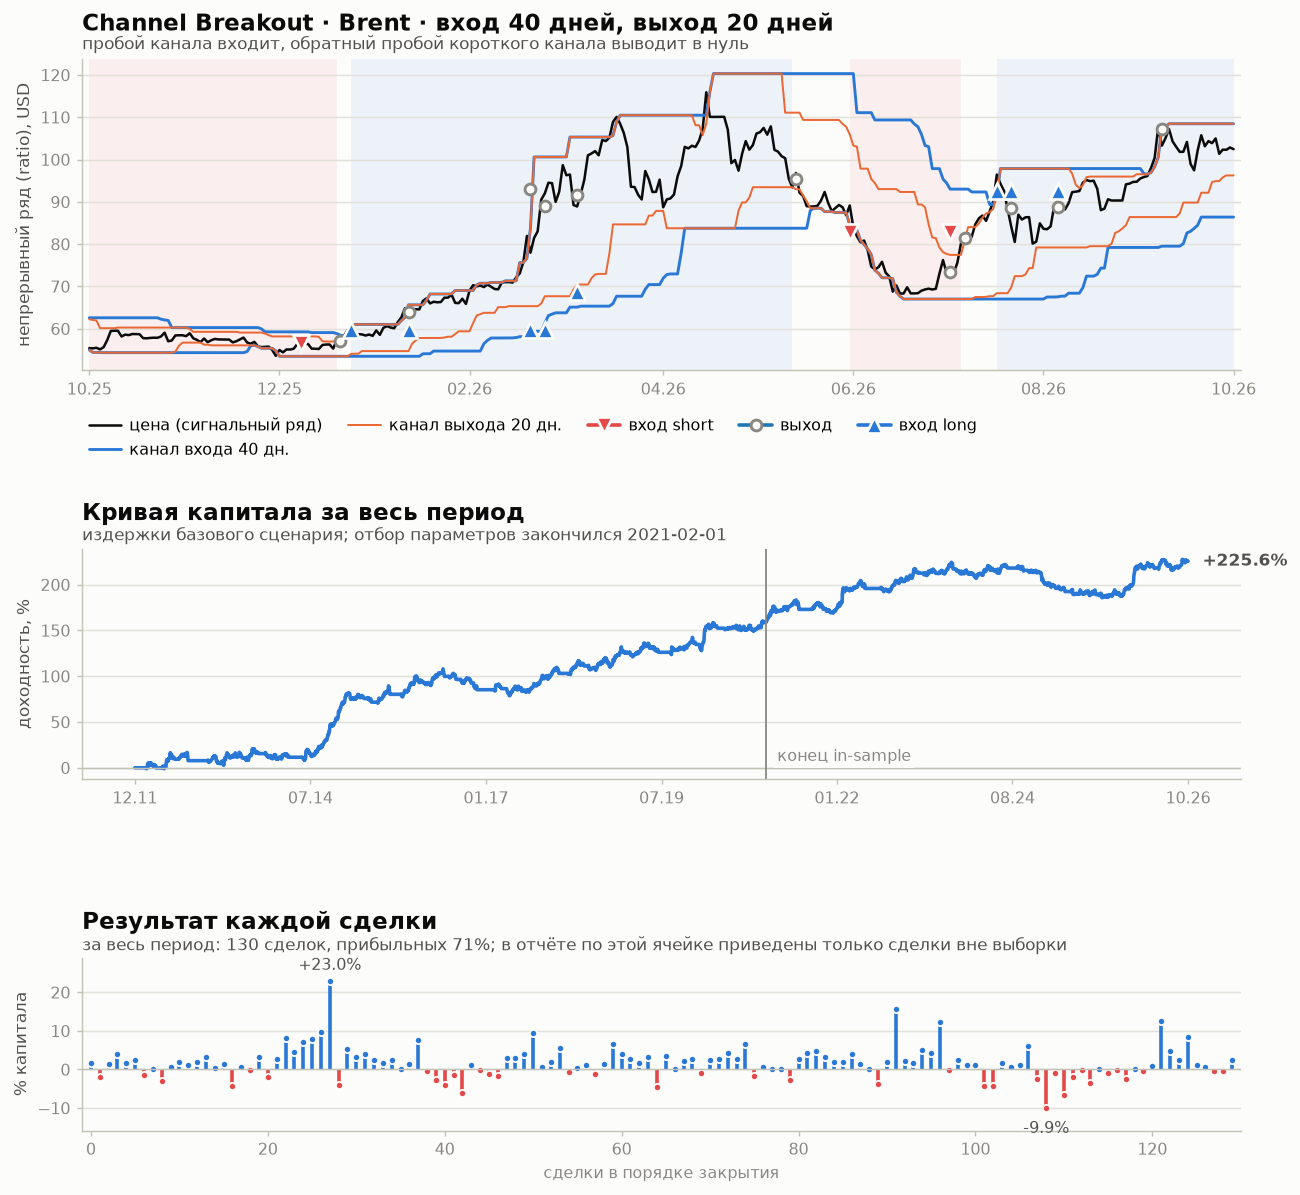

In [9]:
trades_figure(
    "3_breakout", "BR", "BR", window=320, overlay=channel_overlay(40, 20),
    title="Channel Breakout · Brent · вход 40 дней, выход 20 дней",
    mechanism="пробой канала входит, обратный пробой короткого канала выводит в нуль",
)


## 4. Cross-sectional momentum

**Утверждение.** Купить тот рынок, который вырос сильнее, продать тот, который слабее.
Абсолютное направление не важно — важен только порядок.

**Механизм.** Если капитал перетекает в сильные товары, относительная сила сохраняется
дольше, чем абсолютная. Портфель при этом нейтрален к общему уровню цен на сырьё.

**Важная оговорка.** С двумя инструментами кросс-секция вырождается: ранжирование двух
элементов даёт ровно одну длинную и одну короткую ногу, то есть **спред NG против BR**.
Настоящая проверка требует десятков рынков; то, что показано ниже, — не кросс-секционный
моментум, а один конкретный спред, и его провал (OOS Шарп −1.20) говорит о паре NG/BR,
а не о семействе.

**Что видно на графике.** Оранжевая линия — второй рынок, приведённый к началу окна.
Пока она ниже чёрной, этот рынок сильнее и держится long; когда выше — short.

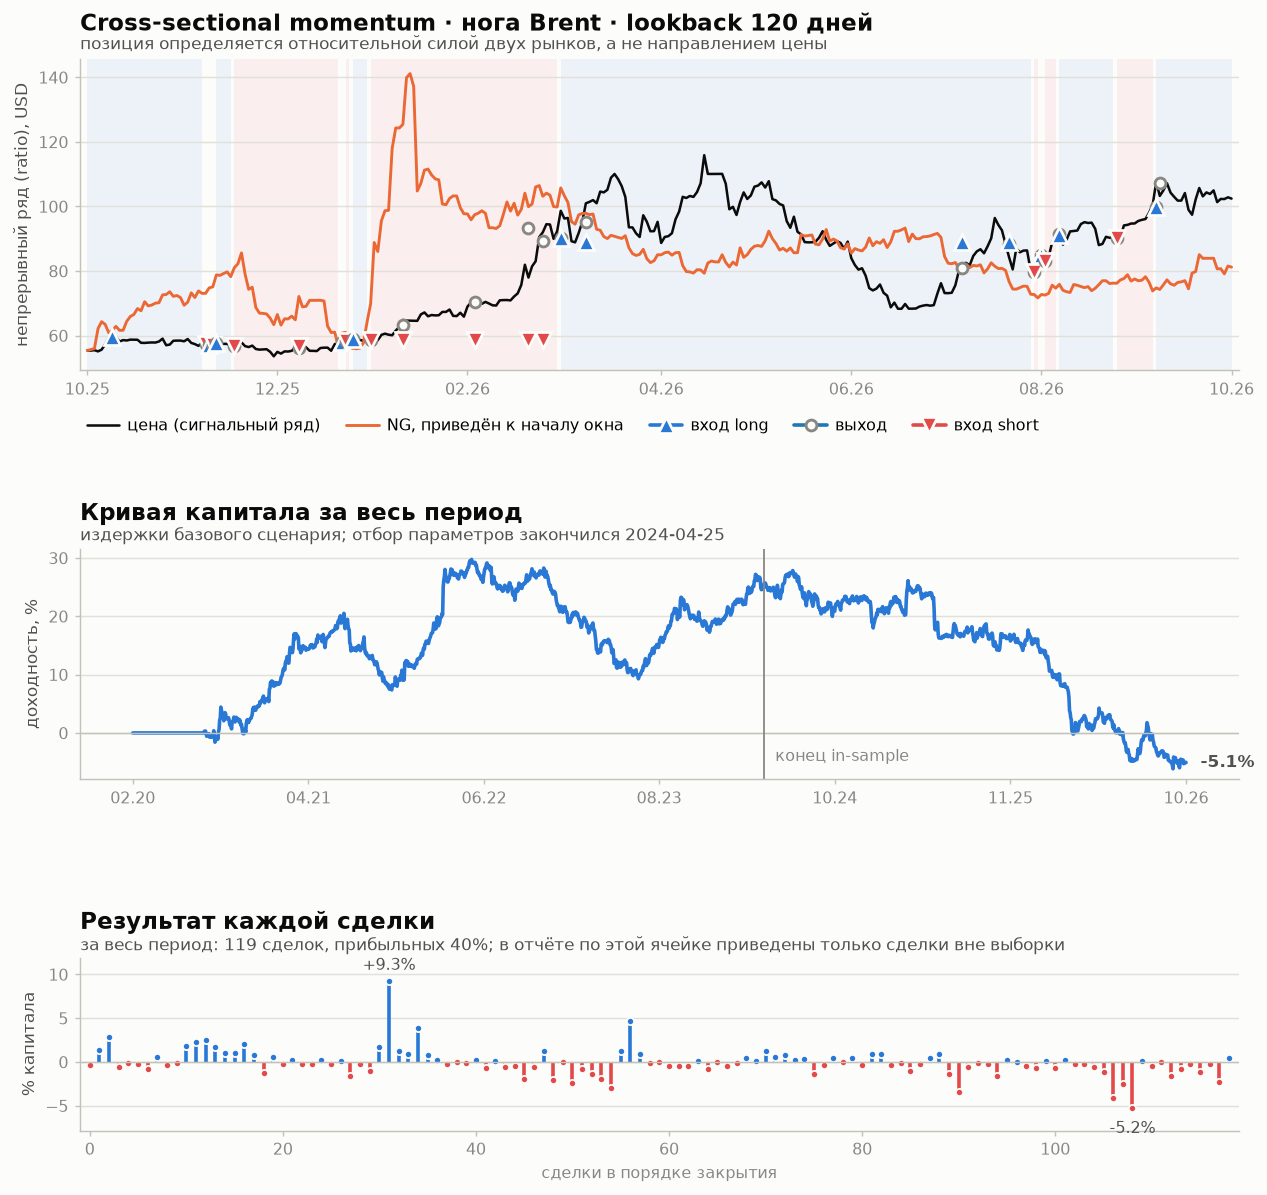

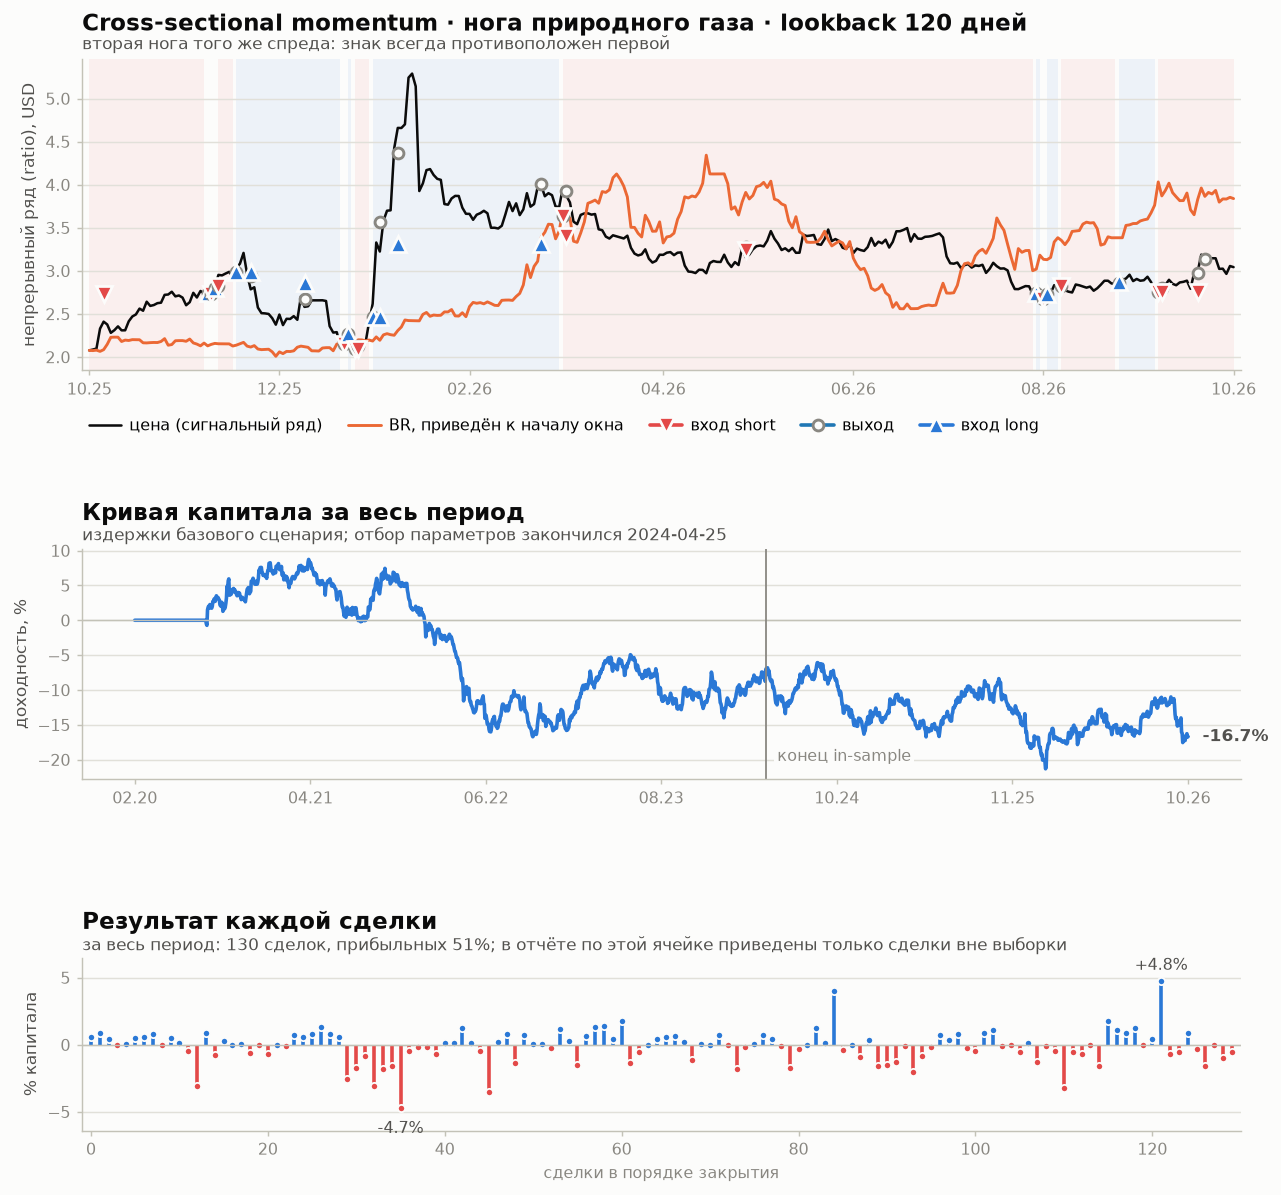

In [10]:
trades_figure(
    "4_cross_sectional", "NG+BR", "BR", window=320, overlay=rival_overlay("NG", 120),
    title="Cross-sectional momentum · нога Brent · lookback 120 дней",
    mechanism="позиция определяется относительной силой двух рынков, а не направлением цены",
)
trades_figure(
    "4_cross_sectional", "NG+BR", "NG", window=320, overlay=rival_overlay("BR", 120),
    title="Cross-sectional momentum · нога природного газа · lookback 120 дней",
    mechanism="вторая нога того же спреда: знак всегда противоположен первой",
)


## 5. Carry / term structure

**Утверждение.** Long при бэквордации (дальний контракт дешевле ближнего), short при
контанго. Доход берётся не из движения цены, а из наклона срочной кривой.

**Механизм.** Бэквордация означает дефицит сейчас: держатель физического товара получает
премию за его наличие. Контанго означает избыток и плату за хранение. Длинная позиция в
бэквордации зарабатывает на каждом ролле, в контанго — теряет.

**Чем измерен carry здесь.** В предсклеенном ряду нет одновременных котировок соседних
контрактов, поэтому наклон восстановлен по **коэффициентам ролла**:
`carry = −ln(ratio)·365/дней`. Значение известно в момент ролла и переносится вперёд —
будущего в нём нет. Это грубый прокси: он обновляется раз в месяц и смещён в сторону уже
реализованного ролла.

**Что видно на графике.** Вторая панель — сам carry с порогом ±0.15. Позиция открывается
только когда наклон выходит за порог: внутри полосы система вне рынка, потому что слабый
наклон не покрывает издержки. По NG carry почти всегда отрицателен (медиана −0.46,
глубокое контанго) — отсюда преобладание коротких позиций.

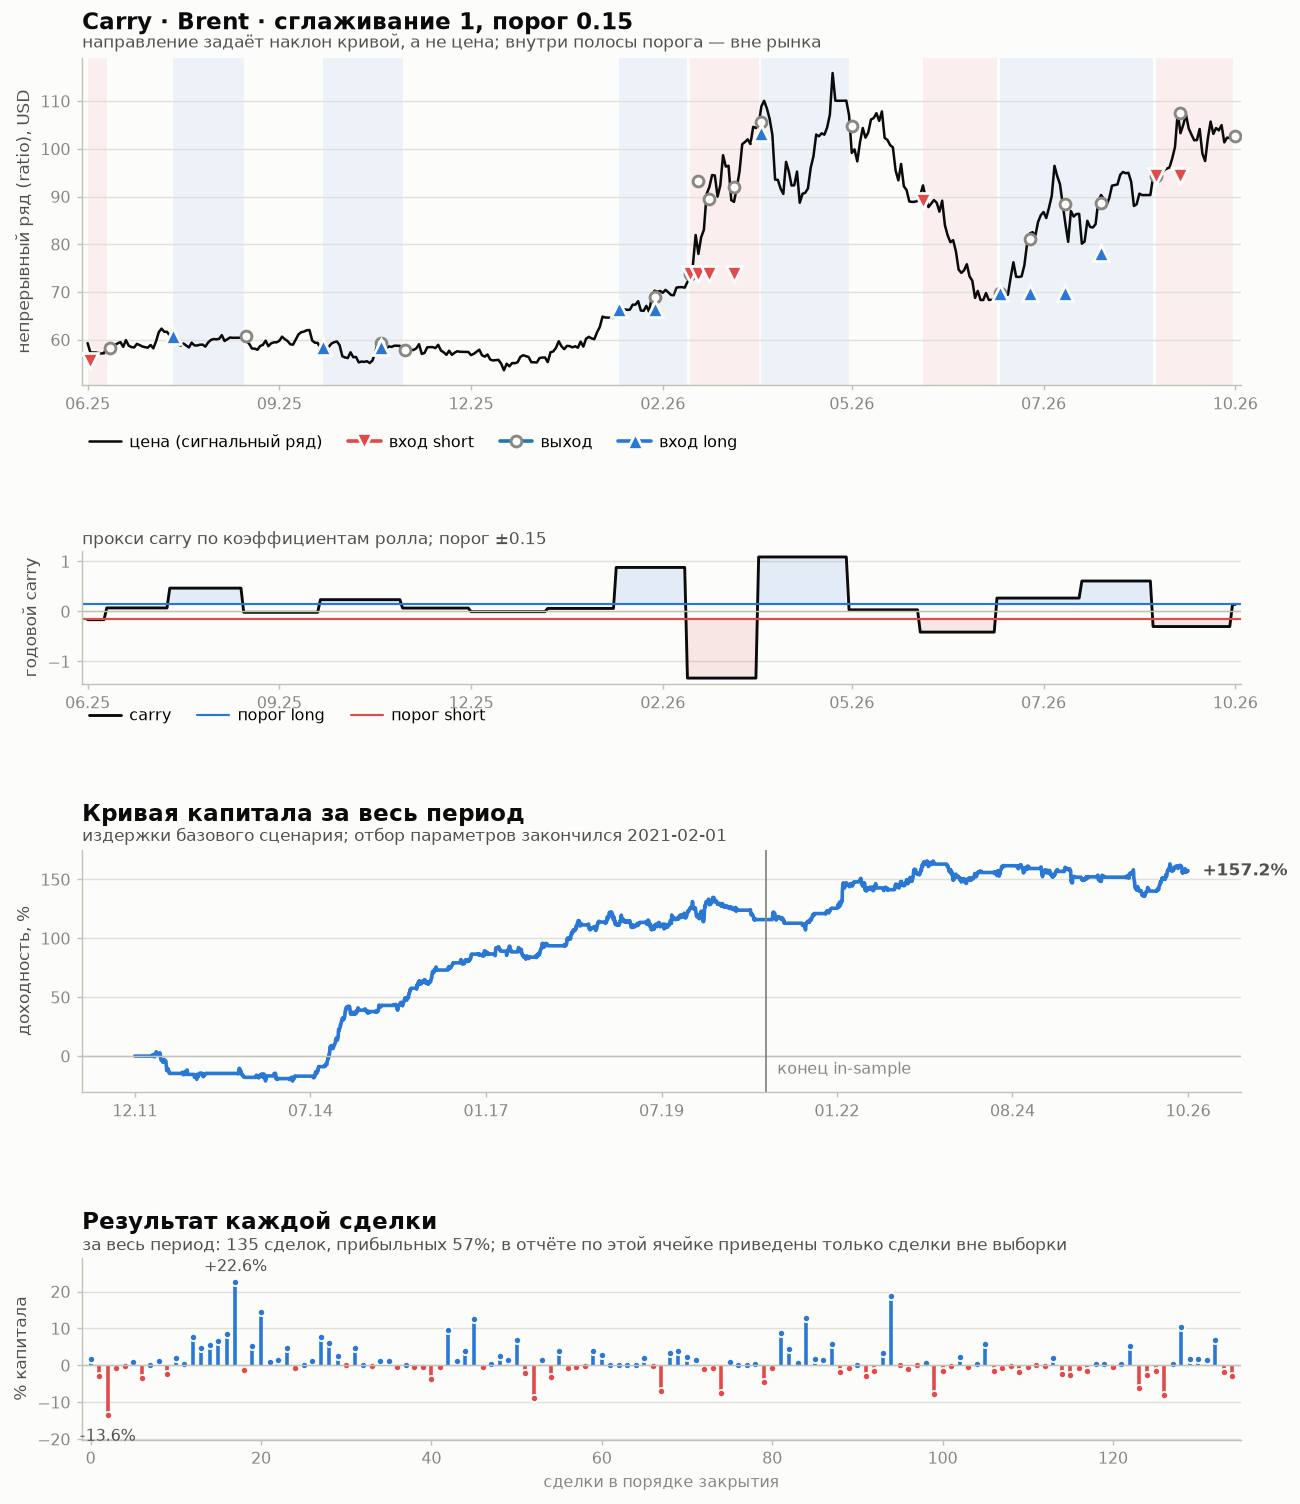

In [11]:
trades_figure(
    "5_carry", "BR", "BR", window=420, overlay=None,
    extra=carry_panel(0.15),
    title="Carry · Brent · сглаживание 1, порог 0.15",
    mechanism="направление задаёт наклон кривой, а не цена; внутри полосы порога — вне рынка",
)


### Carry на газе

Тот же порог, тот же прокси — но знак carry на NG почти всегда отрицателен, и система
стоит в короткой позиции большую часть времени. Положительный OOS-результат здесь
обманчив: **вся сетка этого семейства была убыточной в выборке** (лучший IS Шарп −0.12),
то есть подтверждать было нечего, а PBO 0.73 говорит, что отбор выбирал шум.

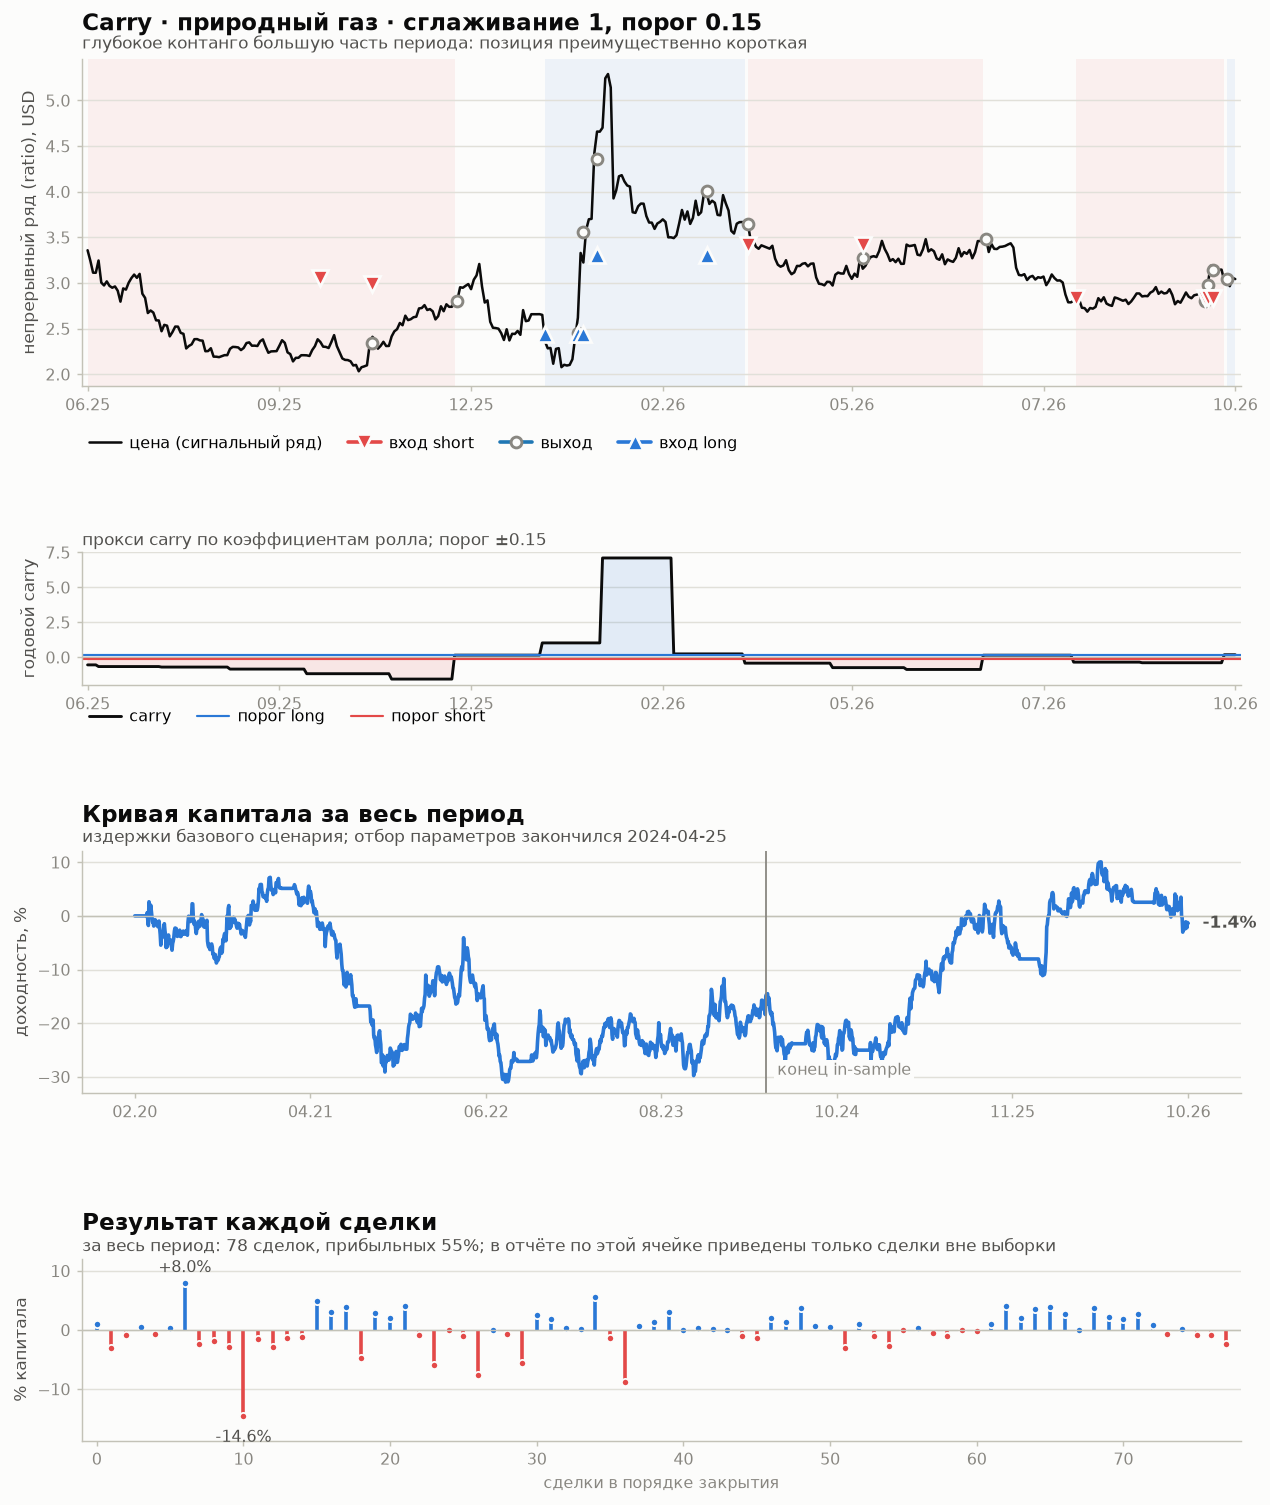

In [12]:
trades_figure(
    "5_carry", "NG", "NG", window=420, overlay=None,
    extra=carry_panel(0.15),
    title="Carry · природный газ · сглаживание 1, порог 0.15",
    mechanism="глубокое контанго большую часть периода: позиция преимущественно короткая",
)


## 6. MA + portfolio diversification

**Утверждение.** То же правило двух средних, но применённое к каждому рынку портфеля, по
половине риска на ногу. Утверждение здесь не про сигнал, а про **диверсификацию**:
сумма двух независимых трендовых ног должна быть ровнее, чем каждая по отдельности.

**Механизм.** Если тренды на газе и нефти не синхронны, их просадки не совпадают, и
волатильность суммы меньше суммы волатильностей.

**Что видно на графике.** Две ноги с одинаковым правилом (SMA 20 против SMA 100) и
независимыми сигналами. Диверсификация действительно работает по форме: максимальная
серия убыточных месяцев здесь самая короткая из всех двенадцати ячеек — 2 месяца.
Но PBO 0.93 — самый высокий в прогоне: отбор пары средних на двух рынках почти
гарантированно выбирает конфигурацию, которая вне выборки окажется хуже медианной.

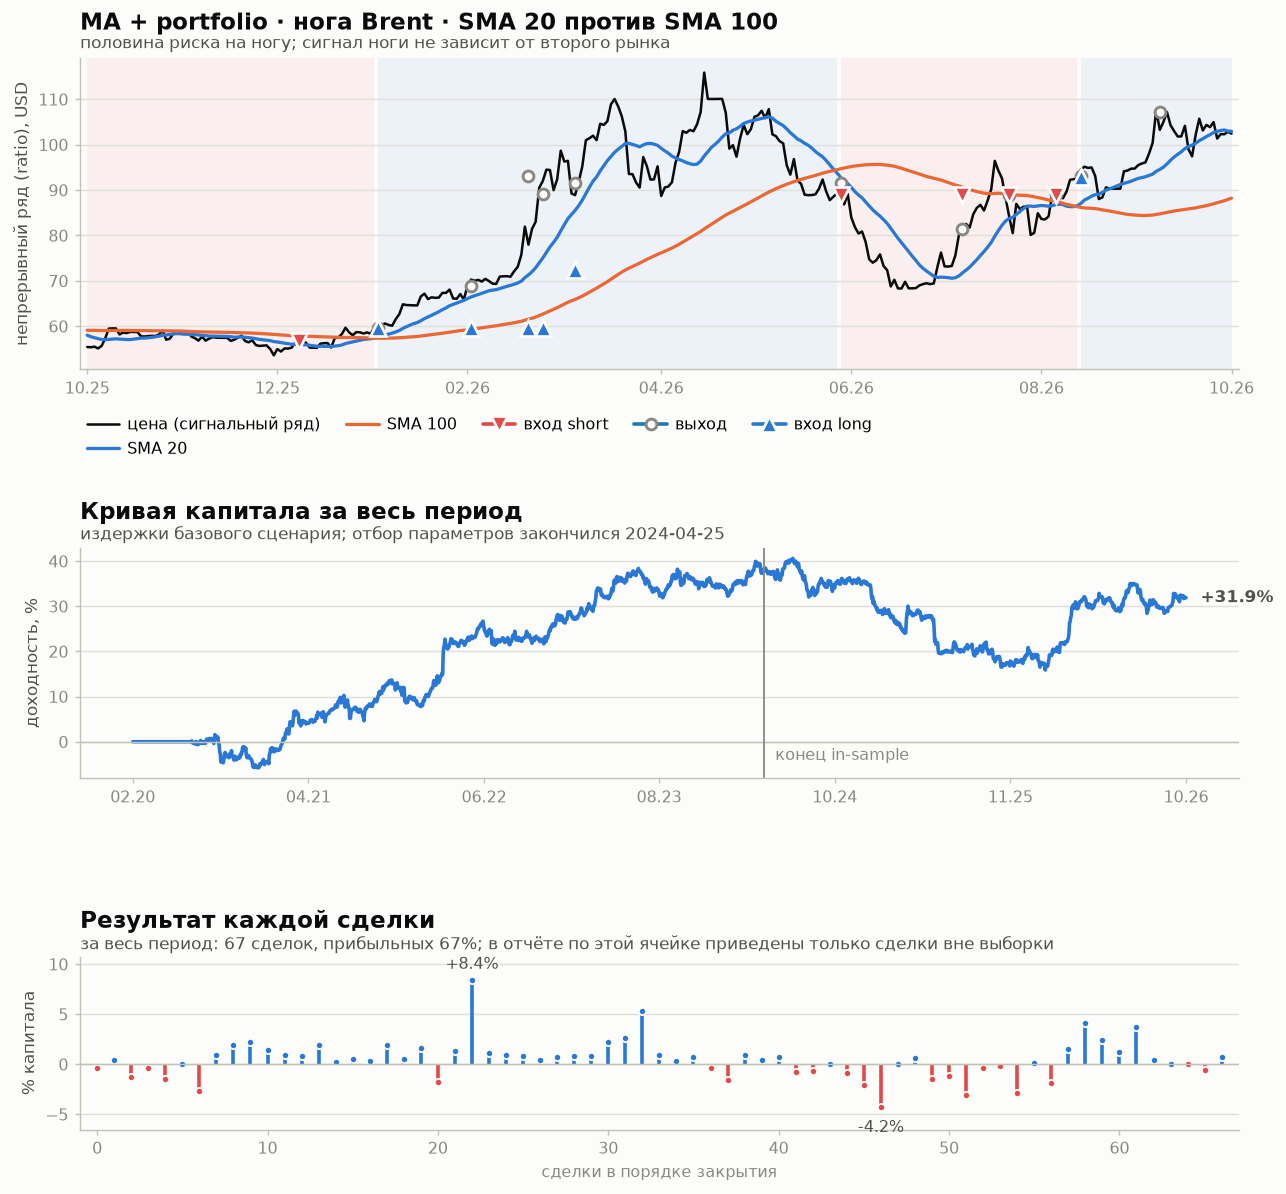

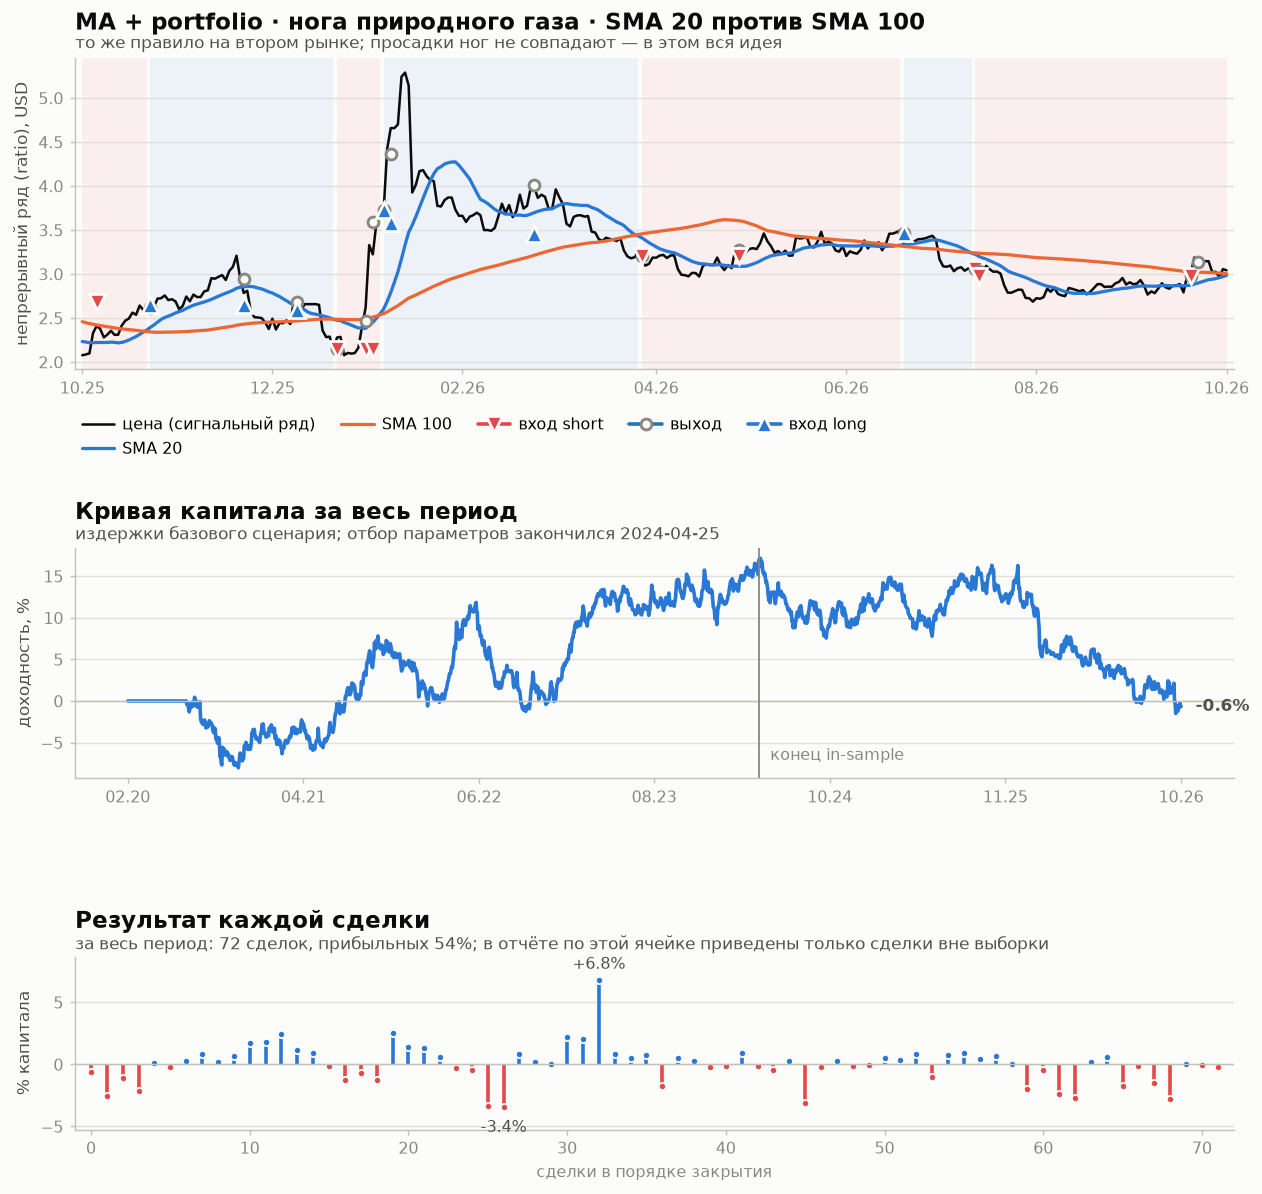

In [13]:
trades_figure(
    "6_portfolio_ma", "NG+BR", "BR", window=320, overlay=ma_overlay(20, 100),
    title="MA + portfolio · нога Brent · SMA 20 против SMA 100",
    mechanism="половина риска на ногу; сигнал ноги не зависит от второго рынка",
)
trades_figure(
    "6_portfolio_ma", "NG+BR", "NG", window=320, overlay=ma_overlay(20, 100),
    title="MA + portfolio · нога природного газа · SMA 20 против SMA 100",
    mechanism="то же правило на втором рынке; просадки ног не совпадают — в этом вся идея",
)


## 7. Momentum + reversal

**Утверждение.** На горизонте 3–12 месяцев доходности продолжаются, на горизонте 1.5–3 лет
разворачиваются. Сигнал складывает знак среднесрочного моментума и **обратный** знак
долгосрочной доходности, с равными весами.

**Механизм.** Два разных процесса на двух разных горизонтах: медленная диффузия информации
даёт моментум, а возврат цены к издержкам производства — реверсию. Комбинация должна
снимать оба.

**Что видно на графике.** Две линии-ориентира: цена 60 дней назад (моментум) и цена
750 дней назад (реверсия). Когда компоненты согласны, сигнал равен ±1 и позиция полная;
когда расходятся — ровно нуль, и система выходит из рынка. Поэтому здесь много периодов
без заливки фона.

**Чем система ломается.** Реверсия с горизонтом 750 дней требует 2–3 полных цикла, чтобы
её вообще можно было проверить. На 15 годах Brent таких циклов 5–6, на 6 годах газа — один.
Это не вопрос качества кода, а вопрос того, сколько независимых наблюдений есть в истории.

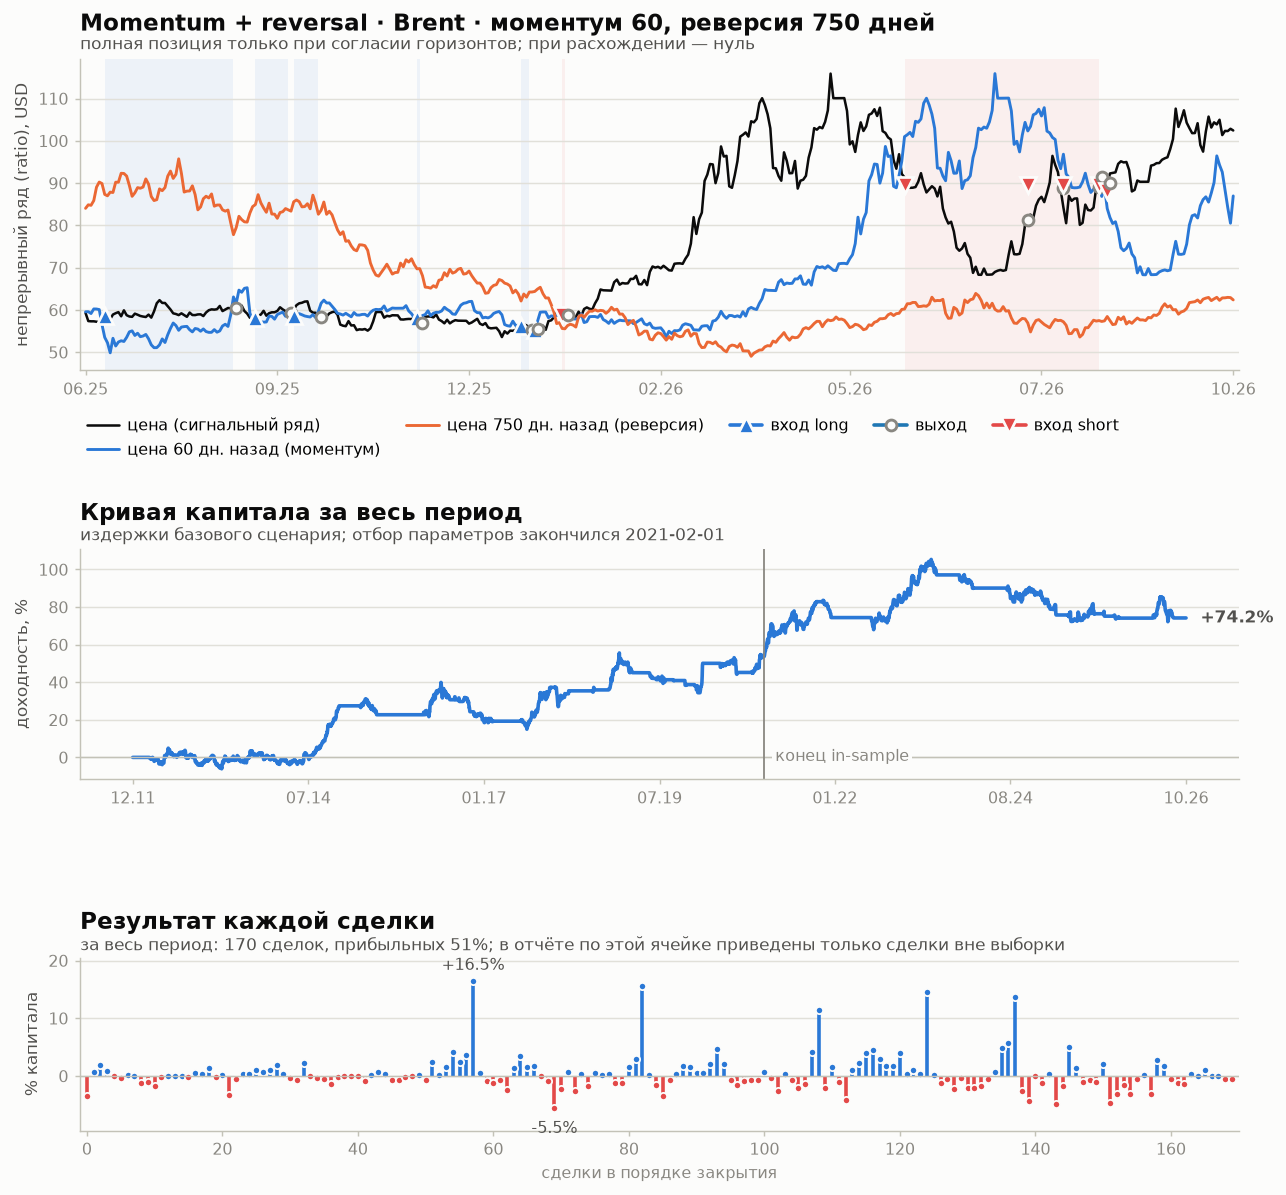

In [14]:
trades_figure(
    "7_mom_reversal", "BR", "BR", window=420,
    overlay=ref_pair(60, "цена 60 дн. назад (моментум)",
                     750, "цена 750 дн. назад (реверсия)"),
    title="Momentum + reversal · Brent · моментум 60, реверсия 750 дней",
    mechanism="полная позиция только при согласии горизонтов; при расхождении — нуль",
)


## Все двенадцать ячеек рядом

Одна панель — одна ячейка, одна серия, один цвет; шкала общая. Семь перекрывающихся
линий на одной оси были бы нечитаемы, а раскраска по номеру серии нарушила бы правило
«цвет следует за сущностью, не за её рангом». Цвет здесь кодирует только знак итога,
и подпись с числом стоит рядом, поэтому смысл не держится на цвете.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


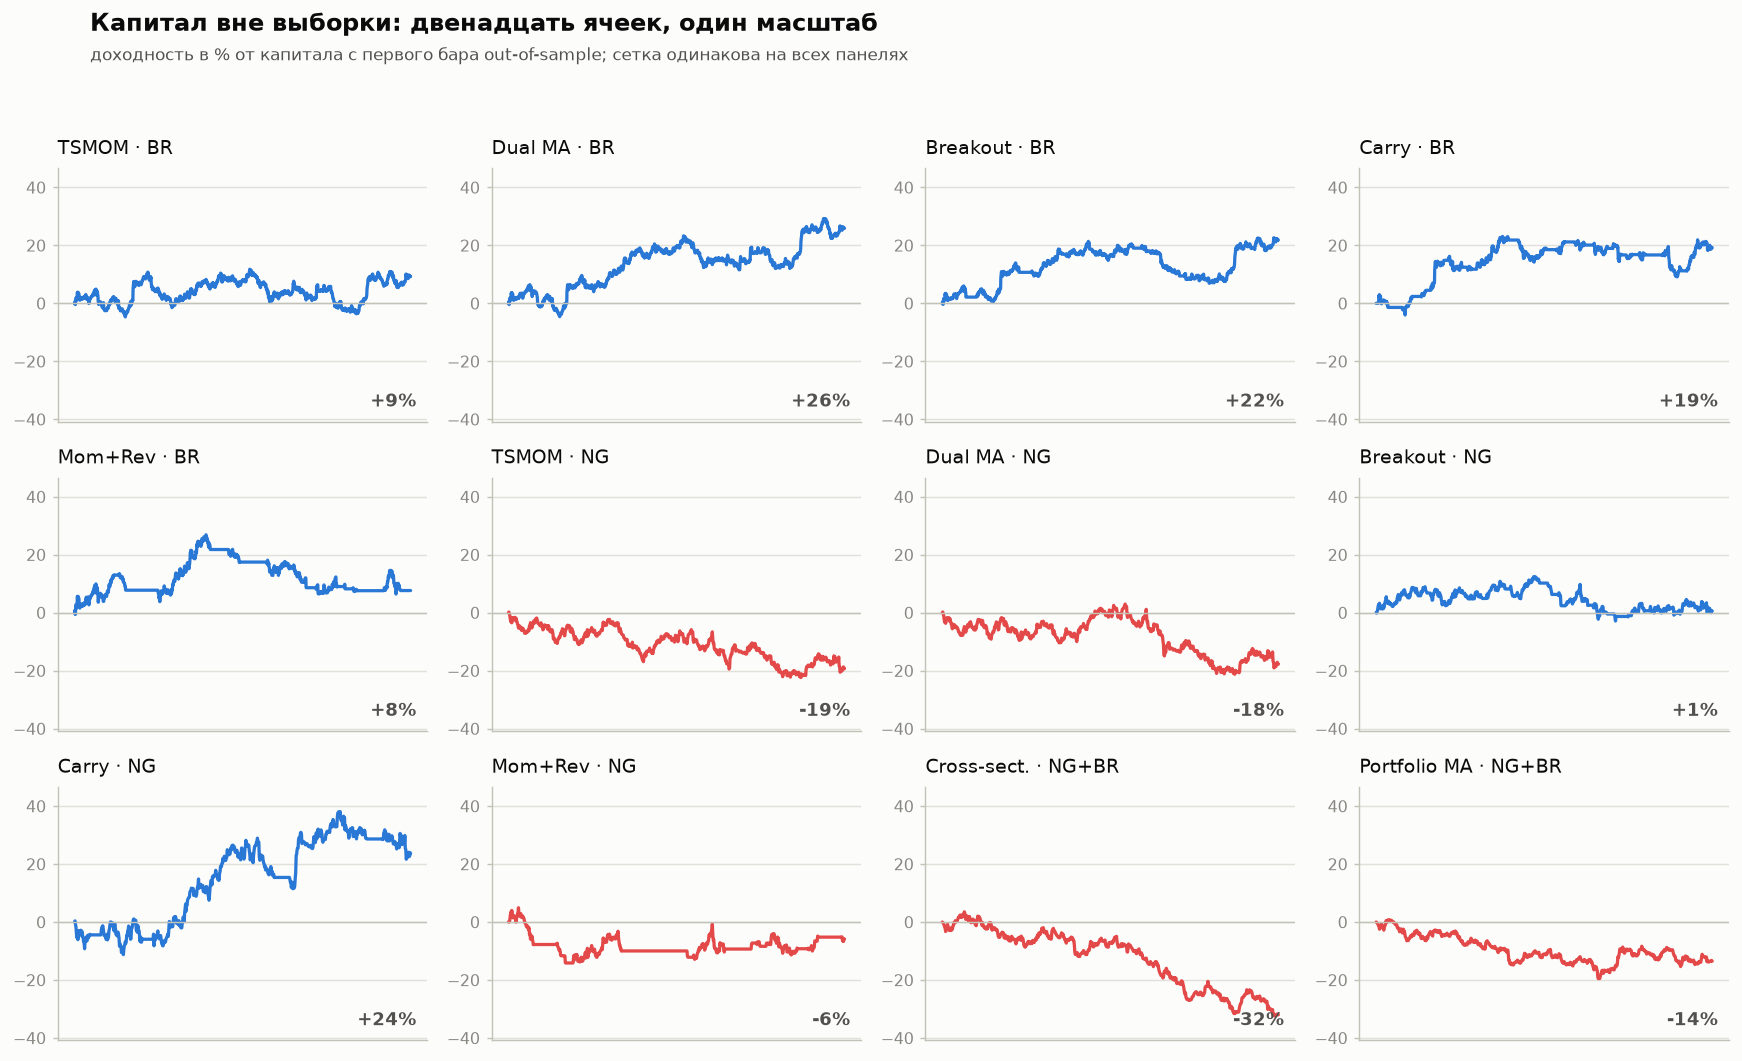

In [15]:
# Малые кратные: одна панель — одна ячейка, одна серия, один цвет.
# Семь перекрывающихся линий на общей оси были бы нечитаемы, а выбор цвета по
# номеру серии нарушил бы правило «цвет следует за сущностью».
order = [("1_tsmom", "BR"), ("2_dual_ma", "BR"), ("3_breakout", "BR"),
         ("5_carry", "BR"), ("7_mom_reversal", "BR"),
         ("1_tsmom", "NG"), ("2_dual_ma", "NG"), ("3_breakout", "NG"),
         ("5_carry", "NG"), ("7_mom_reversal", "NG"),
         ("4_cross_sectional", "NG+BR"), ("6_portfolio_ma", "NG+BR")]
TITLES = {"1_tsmom": "TSMOM", "2_dual_ma": "Dual MA", "3_breakout": "Breakout",
          "4_cross_sectional": "Cross-sect.", "5_carry": "Carry",
          "6_portfolio_ma": "Portfolio MA", "7_mom_reversal": "Mom+Rev"}

fig, axes = plt.subplots(3, 4, figsize=(13.5, 8.2))
fig.suptitle("Капитал вне выборки: двенадцать ячеек, один масштаб",
             color=INK, fontsize=13.5, fontweight="semibold", x=0.055, ha="left", y=0.99)
fig.text(0.055, 0.945, "доходность в % от капитала с первого бара out-of-sample; "
         "сетка одинакова на всех панелях", color=INK_2, fontsize=9.5, ha="left")

curves = {}
for family, market in order:
    legs = [v for (f, m, _), v in LEGS.items() if (f, m) == (family, market)]
    eq = sum((leg["equity"] - H.CAPITAL for leg in legs), start=0.0) + H.CAPITAL
    oos = RA.split(legs[0]["bars"].index)[1]
    eq = eq.reindex(oos).dropna()
    curves[(family, market)] = (eq / float(eq.iloc[0]) - 1.0) * 100.0

lo = min(float(c.min()) for c in curves.values())
hi = max(float(c.max()) for c in curves.values())
pad = (hi - lo) * 0.12
for ax, key in zip(axes.ravel(), order):
    c = curves[key]
    final = float(c.iloc[-1])
    frame(ax, "", "", ylabel="")
    ax.plot(np.arange(len(c)), c.to_numpy(float),
            color=LONG if final > 0 else SHORT, linewidth=1.8)
    ax.axhline(0, color=AXIS, linewidth=0.8)
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_title(f"{TITLES[key[0]]} · {key[1]}", color=INK, fontsize=10.5,
                 loc="left", pad=8)
    ax.text(0.97, 0.06, f"{final:+.0f}%", transform=ax.transAxes, ha="right",
            color=INK_2, fontsize=10, fontweight="semibold")
    ax.set_xticks([])
for ax in axes.ravel()[len(order):]:
    ax.axis("off")
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.93))
plt.show()


## Что показывают эти графики, а что нет

**Показывают.** Что каждая система делает механически: где входит, сколько держит,
как часто переворачивается, чем платит за оборот. На панелях сделок видно то, чего не
видно ни в одной таблице: у TSMOM на Brent 135 сделок и 14% капитала в издержках, у
Dual MA на том же рынке — 69 сделок и 5%, а правило отличается только способом
измерить тот же тренд.

**Не показывают.** Что какая-либо из них работает. Все двенадцать ячеек получили
вердикт `REJECTED`: вне выборки ни одна не достигает p ≤ 0.05 даже без поправки на
множественную проверку, а лучший дефлированный Шарп — 0.83 против порога 0.90.
Красивая кривая капитала на панели — это один путь из многих возможных, и
бутстрэп-интервал на Шарп включает нуль во всех двенадцати случаях.

Главное, что стоит унести из раздела «результат каждой сделки»: итог почти всегда
держится на горстке сделок. Убрать три лучшие — и у большинства ячеек не остаётся
ничего. Это не дефект стратегий, а свойство трендовых систем, и именно поэтому
атака `drop_best_trades` входит в набор фальсификации.